# Environment Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from sklearn.metrics import precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay

# Load the processed data from previous steps (simulated here for continuity)
# In practice, you might load this from a saved parquet file or re-run the pipeline transform
import sys
sys.path.append('../')
from src.features import CreditRiskFeatureEngineer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import xgboost as xgb

# 1. Load Data
df = pd.read_csv('../data/cs-training.csv').drop('Unnamed: 0', axis=1, errors='ignore')
X = df.drop('SeriousDlqin2yrs', axis=1)
y = df['SeriousDlqin2yrs']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 2. Re-create preprocessor
preprocessor = Pipeline([
    ('feature_engineer', CreditRiskFeatureEngineer()),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

# 3. Train the final model (Using hypothetical best params from Phase 4)
best_xgb = xgb.XGBClassifier(
    objective='binary:logistic', eval_metric='auc', scale_pos_weight=14.0,
    max_depth=5, learning_rate=0.05, n_estimators=200, subsample=0.8, random_state=42
)
best_xgb.fit(X_train_proc, y_train)

# Get predicted probabilities
y_prob = best_xgb.predict_proba(X_test_proc)[:, 1]
print("Model and Data loaded successfully.")

Matplotlib is building the font cache; this may take a moment.


Custom transformer 'CreditRiskFeatureEngineer' initialized successfully.
Model and Data loaded successfully.


# Precision-Recall Threshold Tuning

Optimal Probability Threshold (Max F1): 0.7649
Precision at Optimal: 0.3931
Recall at Optimal: 0.5327


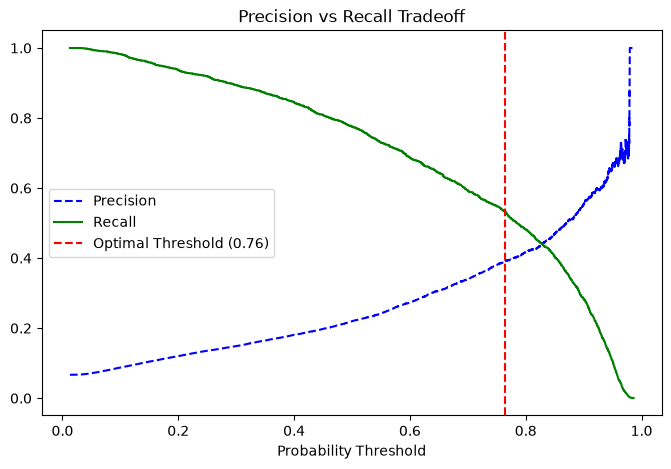

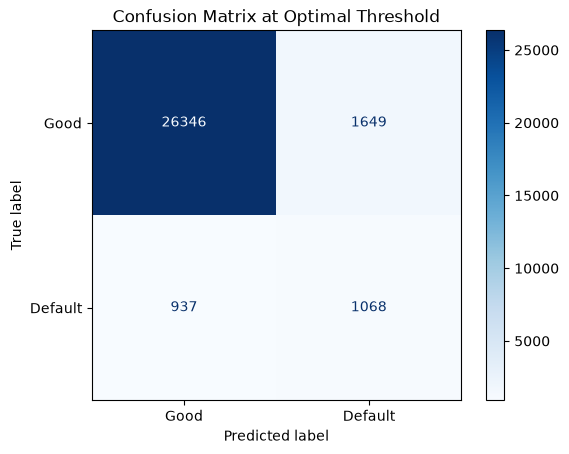

In [2]:
precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)

# Calculate F1 score for each threshold to find the mathematical balance
# (Adding a tiny epsilon to prevent division by zero)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-9)
optimal_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[optimal_idx]

print(f"Optimal Probability Threshold (Max F1): {optimal_threshold:.4f}")
print(f"Precision at Optimal: {precisions[optimal_idx]:.4f}")
print(f"Recall at Optimal: {recalls[optimal_idx]:.4f}")

# Plot the curve
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], 'b--', label='Precision')
plt.plot(thresholds, recalls[:-1], 'g-', label='Recall')
plt.axvline(x=optimal_threshold, color='r', linestyle='--', label=f'Optimal Threshold ({optimal_threshold:.2f})')
plt.xlabel('Probability Threshold')
plt.legend()
plt.title('Precision vs Recall Tradeoff')
plt.show()

# Apply the custom threshold
y_pred_custom = (y_prob >= optimal_threshold).astype(int)

# Display the resulting Confusion Matrix
cm = confusion_matrix(y_test, y_pred_custom)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Good', 'Default'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix at Optimal Threshold")
plt.show()

# SHAP Feature Importance

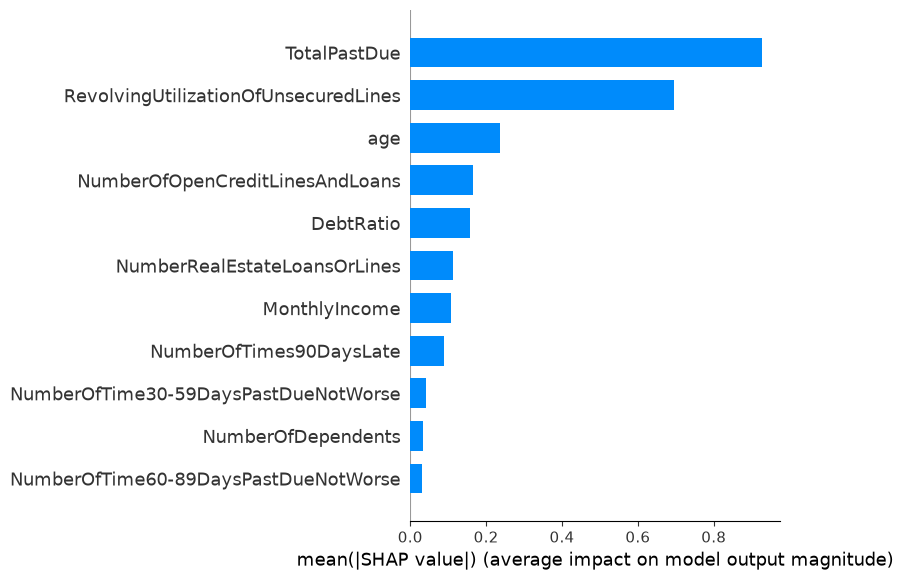

Explanation for Customer Index 0:


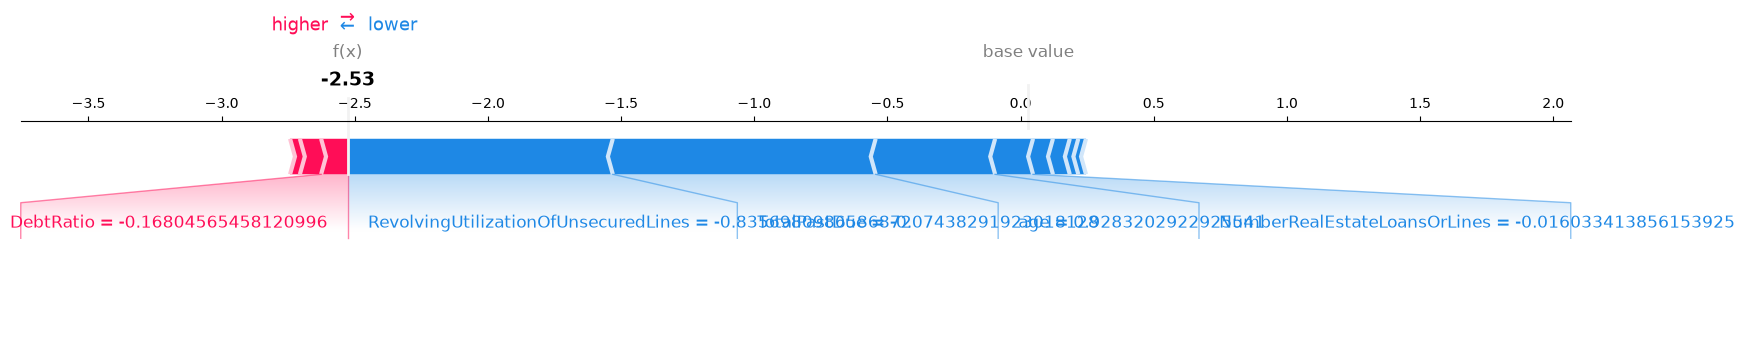

In [3]:
# Ensure shap is installed: pip install shap
import shap

# Initialize the SHAP explainer on the trained XGBoost model
explainer = shap.TreeExplainer(best_xgb)

# Calculate SHAP values for a subset of the test data (computationally heavy)
# We must pass the column names back to the numpy array for readable charts
feature_names = list(X.columns) + ['TotalPastDue']
X_test_df = pd.DataFrame(X_test_proc, columns=feature_names)
shap_values = explainer.shap_values(X_test_df.iloc[:1000])

# Plot Global Feature Importance (What drives the model overall?)
shap.summary_plot(shap_values, X_test_df.iloc[:1000], plot_type="bar")

# Plot Local Feature Importance (Why was THIS specific person rejected?)
# Let's look at the first customer in the test set
print("Explanation for Customer Index 0:")
shap.force_plot(
    explainer.expected_value, 
    shap_values[0,:], 
    X_test_df.iloc[0,:], 
    matplotlib=True
)

# Serializing the Enterprise Pipeline

In [4]:
import os

# 1. Create the final unified pipeline
production_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', best_xgb)
])

# 2. Ensure the artifacts directory exists
os.makedirs('../artifacts', exist_ok=True)

# 3. Save the unified pipeline using joblib
artifact_path = '../artifacts/credit_scoring_pipeline_v1.joblib'
joblib.dump(production_pipeline, artifact_path)

print(f"Production pipeline successfully saved to: {artifact_path}")

# Note: We also save the optimal threshold to use in our API logic later
with open('../artifacts/optimal_threshold.txt', 'w') as f:
    f.write(str(optimal_threshold))

Production pipeline successfully saved to: ../artifacts/credit_scoring_pipeline_v1.joblib
